# MRP / 08 — When do large MNQ 5-minute bars happen? (descriptive, 2020–2025)

Descriptive only: no rule is selected or tested, and 2026 stays sealed. Anything that looks tradable here is a hypothesis for a new pre-registration, confirmed only on 2026.

Two definitions of "large":
- **relative**: |z| ≥ 3 (the MRP 001 volatility model). The time-of-day profile is part of σ̂, so a bar at a busy time (08:30, 09:30 New York) must move more to count. This tells you when moves are *surprising*.
- **absolute**: the bar's move in ticks is in the top 1% of all eligible bars, whatever the time. This tells you when the *biggest moves in ticks* happen.

Clock times are New York (bar open time). Marked slots: 08:30 releases (CPI, payrolls, claims, PPI, retail sales, GDP), 09:30 cash open, 10:00 releases, 14:00 / 14:30 FOMC statement and press conference (FOMC days, from the Federal Reserve calendar), 16:00 cash close.

Optional: put a release calendar at `src/equity_trading/reference/us_macro_calendar.csv` (columns `date,time_ny,event`, e.g. `2024-03-12,08:30,CPI`) and section 7 reports the large-bar rate per event type.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("MRP_SYNTHETIC") == "1"
if SYNTHETIC:   # separate folder: the reversal smoke data has a planted reversal and no FX effect
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("MRP_REV_SYNTH_DIR") or tempfile.mkdtemp(prefix="mrp_rev_")
    os.environ["MRP_REV_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import reversal as V
from equity_trading import big_bars as B

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
D = dt.date
OUT = Path("08"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
print("engines", P.MRP_VERSION, V.REV_VERSION, B.BB_VERSION, "| synthetic" if SYNTHETIC else "| real data")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    P.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.test[1], CFG, beta_jpy=0.0,
                      reversal_points=6.0, tails_df=4)


engines 0.1.1 0.2.0 0.1.0 | real data


In [2]:
K, TOP_Q = 3.0, 0.01
END = CFG.test[1]
REFITS = tuple(CFG.refits_train) + tuple(CFG.refits_test)
FIRST_FIT = (CFG.train[0], REFITS[0])
grid = P.load_grid(CFG.warmup_start, END, CFG)
sig2 = V.event_sigma(grid, FIRST_FIT, REFITS, END, CFG)
bt = V.bar_table(grid, sig2, CFG)
bt = bt[(bt["trade_date"] >= CFG.train[0]) & (bt["trade_date"] <= END)]
e = B.bar_events(bt, K, TOP_Q)
print(f"{len(e):,} eligible bars, {e['trade_date'].nunique()} CME days")
print(f"relative (|z| >= {K:g}): {int(e['big_z'].sum()):,} bars ({e['big_z'].mean():.2%})")
print(f"absolute (top {TOP_Q:.0%} in ticks, >= {e.attrs['abs_threshold_ticks']:.0f} ticks): {int(e['big_abs'].sum()):,} bars")
display(e.groupby("year")[["big_z", "big_abs"]].agg(["sum", "mean"]).round(4))
print("median move of large bars, ticks:", e.loc[e.big_z, "move_ticks"].median(), "(relative)",
      e.loc[e.big_abs, "move_ticks"].median(), "(absolute)")

405,647 eligible bars, 1502 CME days
relative (|z| >= 3): 2,988 bars (0.74%)
absolute (top 1% in ticks, >= 194 ticks): 4,057 bars


big_z         big_abs        
       sum    mean     sum    mean
year                              
2020   584  0.0085     511  0.0074
2021   399  0.0057     293  0.0042
2022   686  0.0107     923  0.0144
2023   370  0.0053     222  0.0032
2024   435  0.0068     560  0.0087
2025   514  0.0074    1548  0.0223

median move of large bars, ticks: 135.83520307668817 (relative) 243.52689445576135 (absolute)


## 1. Time of day (New York)

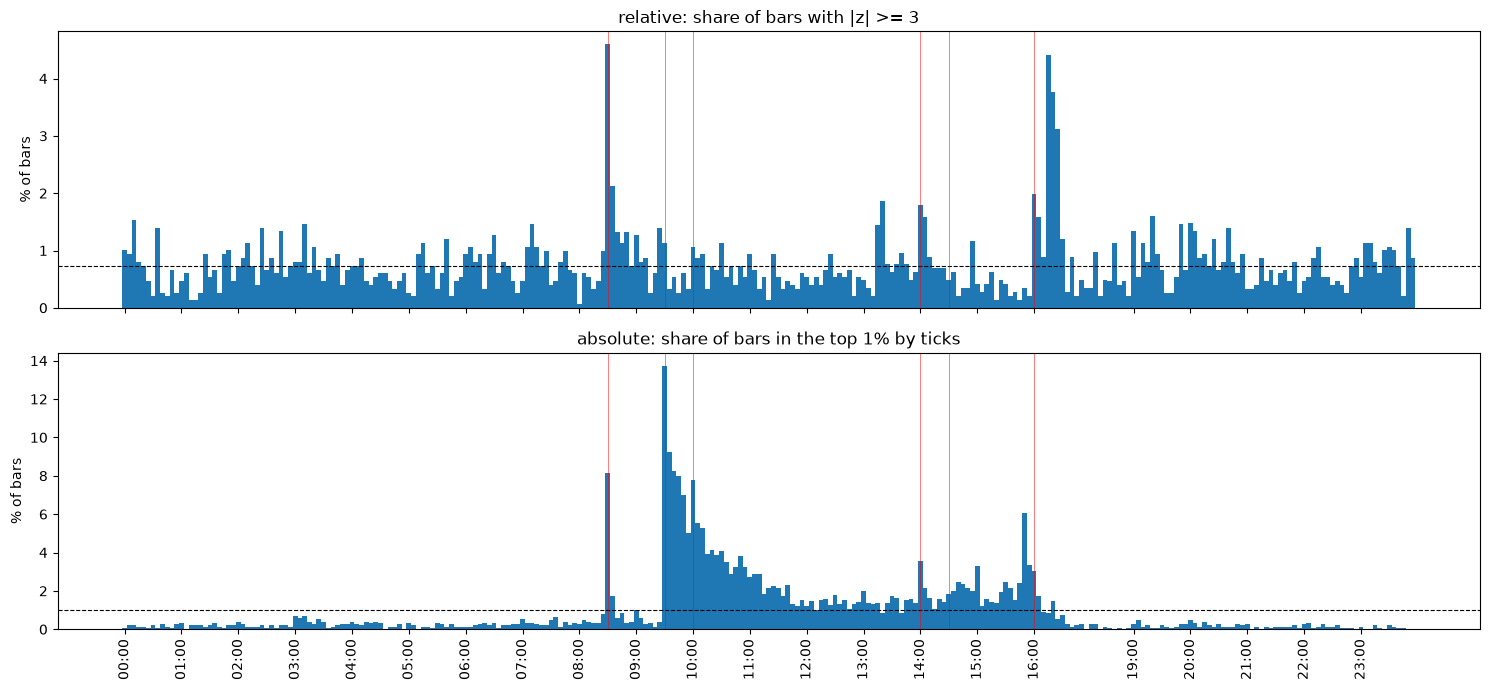

top 15 slots by absolute large-bar rate:


,bars,big,rate,lift,share_of_all_big
ny_time,,,,,
09:30,1501,206,0.1372,13.7224,0.0508
09:35,1502,139,0.0925,9.2531,0.0343
09:40,1502,124,0.0826,8.2546,0.0306
08:30,1502,122,0.0812,8.1214,0.0301
09:45,1502,120,0.0799,7.9883,0.0296
10:00,1502,117,0.0779,7.7886,0.0288
09:50,1502,105,0.0699,6.9898,0.0259
15:50,1454,88,0.0605,6.0515,0.0217
10:05,1502,83,0.0553,5.5252,0.0205


top 15 slots by relative large-bar rate:


,bars,big,rate,lift,share_of_all_big
ny_time,,,,,
08:30,1502,69,0.0459,6.2366,0.0231
16:15,1089,48,0.0441,5.9839,0.0161
16:20,1089,41,0.0376,5.1112,0.0137
16:25,1089,34,0.0312,4.2386,0.0114
08:35,1502,32,0.0213,2.8923,0.0107
16:00,1454,29,0.0199,2.7077,0.0097
13:20,1454,27,0.0186,2.5210,0.0090
14:00,1454,26,0.0179,2.4276,0.0087
19:20,1498,24,0.0160,2.1750,0.0080


In [3]:
rz, ra = B.slot_rates(e, "big_z"), B.slot_rates(e, "big_abs")
fig, ax = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for a, r, t in ((ax[0], rz, f"relative: share of bars with |z| >= {K:g}"), (ax[1], ra, f"absolute: share of bars in the top {TOP_Q:.0%} by ticks")):
    x = np.arange(len(r))
    a.bar(x, r["rate"] * 100, width=1.0)
    a.axhline(r["big"].sum() / r["bars"].sum() * 100, color="k", lw=.8, ls="--")
    a.set_ylabel("% of bars"); a.set_title(t)
    for name, tm in B.MARKS.items():
        if tm in r.index:
            a.axvline(list(r.index).index(tm), color="r", lw=.6, alpha=.6)
ticks = [i for i, s in enumerate(rz.index) if s.endswith(":00")]
ax[1].set_xticks(ticks); ax[1].set_xticklabels([rz.index[i] for i in ticks], rotation=90)
plt.tight_layout(); plt.savefig(OUT / "time_of_day.png", dpi=110); plt.show()
print("top 15 slots by absolute large-bar rate:"); display(ra.sort_values("rate", ascending=False).head(15).round(4))
print("top 15 slots by relative large-bar rate:"); display(rz.sort_values("rate", ascending=False).head(15).round(4))

## 2. Scheduled-release and session slots: share of bars vs share of large bars

In [4]:
for flag in ("big_z", "big_abs"):
    print(flag); display(B.mark_table(e, flag).round(4))

big_z


,slot,bars,big,rate,share_of_bars,share_of_big,lift
0,"08:30 releases (CPI, NFP, claims, PPI, retail ...",1502,69,0.0459,0.0037,0.0231,6.2366
1,09:30 cash open,1501,17,0.0113,0.0037,0.0057,1.5376
2,"10:00 releases (ISM, confidence, JOLTS)",1502,16,0.0107,0.0037,0.0054,1.4462
3,14:00 FOMC statement (FOMC days),46,18,0.3913,0.0001,0.0060,53.1230
4,14:30 FOMC press conference (FOMC days),46,2,0.0435,0.0001,0.0007,5.9026
5,16:00 cash close,1454,29,0.0199,0.0036,0.0097,2.7077


big_abs


,slot,bars,big,rate,share_of_bars,share_of_big,lift
0,"08:30 releases (CPI, NFP, claims, PPI, retail ...",1502,122,0.0812,0.0037,0.0301,8.1214
1,09:30 cash open,1501,206,0.1372,0.0037,0.0508,13.7224
2,"10:00 releases (ISM, confidence, JOLTS)",1502,117,0.0779,0.0037,0.0288,7.7886
3,14:00 FOMC statement (FOMC days),46,19,0.4130,0.0001,0.0047,41.2990
4,14:30 FOMC press conference (FOMC days),46,11,0.2391,0.0001,0.0027,23.9099
5,16:00 cash close,1454,44,0.0303,0.0036,0.0108,3.0257


## 3. FOMC days

In [5]:
win = e["ny_time"].isin(["14:00", "14:05", "14:10", "14:15", "14:30", "14:35", "14:40", "14:45"])
f = e[win].groupby(["fomc_day", "ny_time"])[["big_z", "big_abs", "move_ticks"]].agg({"big_z": "mean", "big_abs": "mean", "move_ticks": "median"})
display(f.unstack(0).round(3))
print("share of all absolute-large bars that fall on FOMC days:", round(e.loc[e.fomc_day, "big_abs"].sum() / e["big_abs"].sum(), 4),
      "| FOMC days are", round(e["fomc_day"].mean(), 4), "of bars")

big_z        big_abs        move_ticks         
fomc_day  False  True    False  True       False    True 
ny_time                                                  
14:00     0.006  0.391   0.023  0.413     32.993  154.166
14:05     0.011  0.152   0.015  0.217     27.995   58.469
14:10     0.008  0.043   0.012  0.152     27.993   63.531
14:15     0.006  0.022   0.008  0.087     26.007   69.542
14:30     0.004  0.043   0.011  0.239     29.989  103.473
14:35     0.002  0.130   0.009  0.348     25.993  128.999
14:40     0.001  0.043   0.014  0.348     27.005  102.593
14:45     0.004  0.000   0.020  0.130     25.994  103.576

share of all absolute-large bars that fall on FOMC days: 0.0624 | FOMC days are 0.0308 of bars


## 4. Weekday × hour (% of bars that are large)

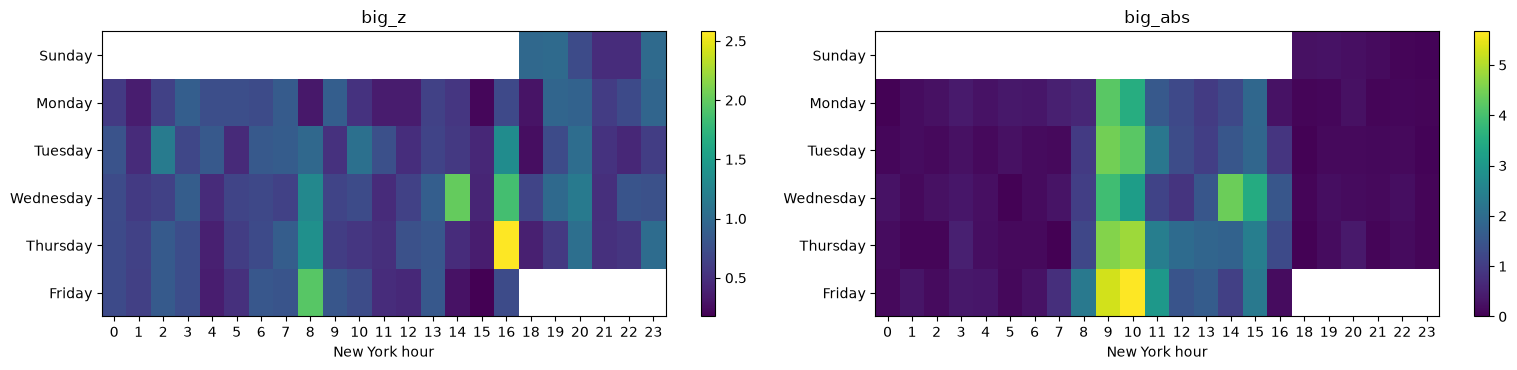

Friday 08:30 bar: first Friday of month (payrolls proxy) vs other Fridays


,big_z,big_abs,move_ticks
first_friday,,,
False,0.031,0.097,37.013
True,0.254,0.358,135.142


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 3.8))
for a, flag in zip(ax, ("big_z", "big_abs")):
    h = B.weekday_hour(e, flag)
    im = a.imshow(h.to_numpy(), aspect="auto", cmap="viridis")
    a.set_yticks(range(len(h))); a.set_yticklabels(h.index); a.set_xticks(range(len(h.columns))); a.set_xticklabels(h.columns)
    a.set_xlabel("New York hour"); a.set_title(flag); plt.colorbar(im, ax=a)
plt.tight_layout(); plt.savefig(OUT / "weekday_hour.png", dpi=110); plt.show()
fri = e[(e["weekday"] == "Friday") & (e["ny_time"] == "08:30")]
print("Friday 08:30 bar: first Friday of month (payrolls proxy) vs other Fridays")
display(fri.groupby("first_friday")[["big_z", "big_abs", "move_ticks"]].agg({"big_z": "mean", "big_abs": "mean", "move_ticks": "median"}).round(3))

## 5. Clustering: do large bars come in bursts?

In [7]:
for flag in ("big_z", "big_abs"):
    print(flag); display(B.clustering(e, flag).round(4)); display(B.per_day(e, flag).round(4))

big_z


,within_bars,p_given_big,p_unconditional,ratio
0,1,0.0479,0.0074,6.5102
1,3,0.0863,0.0211,4.0918
2,6,0.1141,0.0408,2.7992
3,12,0.1459,0.0782,1.8660


,days,days_with_any,share_days_with_any,mean_per_day,top10pct_days_share_of_big
0,1502,1196,0.7963,1.9893,0.2677


big_abs


,within_bars,p_given_big,p_unconditional,ratio
0,1,0.1656,0.0100,16.5781
1,3,0.3604,0.0255,14.1347
2,6,0.5043,0.0430,11.7221
3,12,0.6120,0.0696,8.7923


,days,days_with_any,share_days_with_any,mean_per_day,top10pct_days_share_of_big
0,1502,857,0.5706,2.7011,0.5704


## 6. Through time

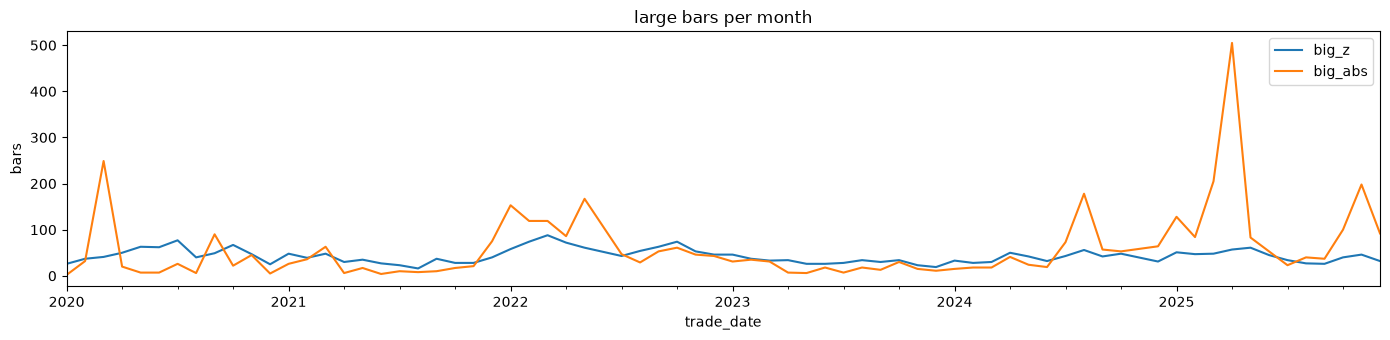

In [8]:
m = e.groupby(pd.to_datetime(e["trade_date"]).dt.to_period("M"))[["big_z", "big_abs"]].sum()
ax = m.plot(figsize=(14, 3.5), title="large bars per month"); ax.set_ylabel("bars")
plt.tight_layout(); plt.savefig(OUT / "per_month.png", dpi=110); plt.show()

## 7. Optional release calendar

In [9]:
cal = B.load_calendar(REPO / "src/equity_trading/reference/us_macro_calendar.csv")
if cal is None:
    print("no calendar file: skipped (see the header cell for the format)")
else:
    for flag in ("big_z", "big_abs"):
        print(flag); display(B.calendar_hits(e, cal, flag).round(3))

no calendar file: skipped (see the header cell for the format)


In [10]:
summary = {"engines": [P.MRP_VERSION, B.BB_VERSION], "synthetic": SYNTHETIC, "k": K, "top_q": TOP_Q,
           "abs_threshold_ticks": e.attrs["abs_threshold_ticks"],
           "marks": {f: B.mark_table(e, f).to_dict("records") for f in ("big_z", "big_abs")},
           "clustering": {f: B.clustering(e, f).to_dict("records") for f in ("big_z", "big_abs")},
           "top_slots_abs": ra.sort_values("rate", ascending=False).head(15).reset_index().to_dict("records"),
           "top_slots_rel": rz.sort_values("rate", ascending=False).head(15).reset_index().to_dict("records")}
(OUT / "summary.json").write_text(json.dumps(summary, indent=1, default=float))
rz.to_csv(OUT / "slots_relative.csv"); ra.to_csv(OUT / "slots_absolute.csv")